# 05 · Resultado final y contraste visual
Aplicamos el ganador de 04 a todos los puntos. Colores de clase en PLY y panel; IDs de instancia conservados en el CSV y en cache/exp_final_ids.npy. Verificamos igualdad exacta de xyz, orden y normales al volver a leer el PLY.

La vista de columnas asigna **un color único por instancia**, sin reciclar la paleta de veinte colores. Incluye xy y lateral para detectar dos filas de columnas superpuestas y caras duplicadas. La tabla de columnas muestra centro, bbox y altura; alto≥5 m distingue fustes largos de soportes parciales. Las posiciones citadas por la revisión visual son una referencia de inspección, no etiquetas usadas por el algoritmo. No afirmamos un censo real ni exactitud.

La tabla base/final incluye la evaluación geométrica con soporte pareado y el control K=11, tamaño de segmentos, cobertura y mayor segmento. ARI/NMI de clases colapsadas se guardan solo como concordancia.

**Ejecución:** IPython en `.venv`, celdas en orden, sin kernel de sockets (nbconvert bloqueado por sandbox). Tiempo: 8.18 s. Logs en `outputs/logs/`; cachés en `outputs/cache/`.

In [1]:
import os, sys, json, time
from pathlib import Path
sys.dont_write_bytecode = True
ROOT = Path.cwd() if Path('src/pcseg').exists() else Path.cwd().parents[1]
sys.path.insert(0,str(ROOT/'src'))
os.environ['MPLCONFIGDIR']=str(ROOT/'outputs/cache/exp_matplotlib')
os.environ['IPYTHONDIR']=str(ROOT/'outputs/cache/exp_ipython')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from IPython.display import display, Image
from threadpoolctl import threadpool_limits
from pcseg.io import read_ply, write_ply, labels_to_rgb
from pcseg.features import voxel_downsample, build_features
from pcseg.metrics import silhouette_sample, davies_bouldin
from pcseg.stages import *
plt.switch_backend('Agg')
thread_limit = threadpool_limits(limits=2)
OUT=ROOT/'outputs'; CACHE=OUT/'cache'; FIG=OUT/'figs'; LOG=OUT/'logs'; ENT=ROOT/'entregable'; ENT.mkdir(exist_ok=True)
START=time.perf_counter()
cloud=read_ply(ROOT/'data/FARO_Scan_Full_Sub1_down3_with_normals.ply')
common_idx=np.load(OUT/'sample_idx.npy')
xyz,rgb,normals=(cloud[k][common_idx] for k in ('xyz','rgb','normals'))
EVAL=build_features(xyz,rgb,normals,use_rgb=True,use_normals=True,use_height=True)
base_table=pd.read_csv(ENT/'clase_metricas.csv')
base=base_table[base_table.seleccionada].iloc[0]
base_labels=np.load(LOG/'clase_labels'/f'{base.id}.npy')
assert len(xyz)==93903 and len(cloud['xyz'])==1647021
print('Muestra común',len(xyz),'Python',sys.executable,sys.version.split()[0])
CLASS_COLORS={'piso':(70,155,70),'techo':(90,140,230),'pared':(190,145,90),
 'plano_horizontal':(145,190,220),'columna':(230,60,55),'viga_horizontal':(245,170,35),
 'viga_o_tuberia':(225,125,25),'tuberia':(25,180,185),
 'equipo_bajo':(155,75,190),'compacto_plausible':(30,200,190),
 'mezcla_no_identificada':(210,110,160),'ruido':(45,45,45)}
def view(points,labels,name,title,classes=None):
    idx=np.random.default_rng(0).choice(len(points),min(35000,len(points)),replace=False)
    p=points[idx]; ls=labels[idx]
    if classes is None: colors=labels_to_rgb(ls)/255.
    else: colors=np.array([CLASS_COLORS[classes[int(v)]] for v in ls])/255.
    fig=plt.figure(figsize=(16,5))
    for i,j in enumerate((1,2)):
        ax=fig.add_subplot(1,3,i+1)
        ax.scatter(p[:,0],p[:,j],c=colors,s=2,alpha=.65,linewidths=0)
        ax.set(xlabel='x (m)',ylabel='y (m)' if j==1 else 'z (m)',aspect='equal',title='Superior' if j==1 else 'Lateral')
    ax=fig.add_subplot(1,3,3,projection='3d'); ax.scatter(*p.T,c=colors,s=1,alpha=.65)
    ax.set(xlabel='x',ylabel='y',zlabel='z',title='3D'); ax.set_box_aspect(np.maximum(np.ptp(p,axis=0),.1))
    if classes:
        names=sorted(set(classes.values()))
        fig.legend(handles=[Patch(color=np.array(CLASS_COLORS[n])/255,label=n) for n in names],loc='lower center',ncol=4,fontsize=8)
    fig.suptitle(title); fig.tight_layout(rect=(0,.12,1,.94) if classes else (0,0,1,.94))
    path=FIG/f'exp_{name}.png'; fig.savefig(path,dpi=140); plt.close(fig); display(Image(filename=str(path)))
def save_run(name,run):
    np.savez_compressed(CACHE/f'exp_{name}.npz',labels=run['labels'],idx=run['idx'],sample_labels=run['sample_labels'])
    serial=[]
    for p in run['planes']:
        serial.append({k:v for k,v in p.items() if k!='inliers'})
    (CACHE/f'exp_{name}_planes.json').write_text(json.dumps(serial,indent=2))
    supports={f'plano_{j}':run['idx'][p['inliers']] for j,p in enumerate(run['planes'])}
    sampled=cloud['xyz'][run['idx']]
    for j,p in enumerate(run['planes']):
        for k,coef in enumerate(p.get('patches',[])):
            mask=np.abs(sampled@np.asarray(coef[:3])+coef[3])<.08
            supports[f'plano_{j}_parche_{k}']=run['idx'][mask]
    np.savez_compressed(CACHE/f'exp_{name}_inliers.npz',**supports)
def load_run(name):
    a=dict(np.load(CACHE/f'exp_{name}.npz'))
    a['planes']=json.loads((CACHE/f'exp_{name}_planes.json').read_text())
    return a
def finish(name, payload):
    payload['segundos_notebook']=time.perf_counter()-START
    (CACHE/f'exp_resumen_{name}.json').write_text(json.dumps(payload,indent=2,default=float))
    print(payload)

from pcseg.propagate import propagate_labels
from sklearn.preprocessing import StandardScaler
BASE_FULL=propagate_labels(xyz,base_labels,cloud['xyz'])
def maps_and_totals(run):
    desc,totals=summarize_classes(cloud['xyz'],run['labels'],run['planes'])
    classes=dict(zip(desc.id,desc.clase_heuristica)); classes[-1]='ruido'
    return desc,totals,classes
def mixture_metrics(desc,totals):
    def pct(name):
        row=totals[totals.clase_heuristica==name]
        return float(row.porcentaje.sum())
    columns=desc[desc.clase_heuristica=='columna']
    high=columns[columns.extension_vertical>=5]
    from sklearn.cluster import DBSCAN
    xy=(high[['x_min','y_min']].to_numpy()+high[['x_max','y_max']].to_numpy())/2
    footprints=DBSCAN(eps=1.5,min_samples=1).fit_predict(xy) if len(high) else []
    distinct=len(set(footprints))
    return dict(n_segmentos_completo=int((desc.id>=0).sum()),mezcla_pct=pct('mezcla_no_identificada'),ruido_completo_pct=pct('ruido'),
        no_resuelto_pct=pct('mezcla_no_identificada')+pct('ruido'),
        n_columnas=int(len(columns)),n_columnas_altas=int((columns.extension_vertical>=5).sum()),n_columnas_altas_distintas=distinct)
def geometry_space():
    path=CACHE/'exp_features_geo.npy'
    if path.exists(): return np.load(path)
    f=local_pca_features(xyz,k=96)
    X=StandardScaler().fit_transform(np.c_[xyz,normals,f['linealidad']])
    np.save(path,X)
    return X


Muestra común 93903 Python /home/evssz/UTEC/6to/machine/clasifica-puntos-pe/.venv/bin/python 3.12.15


{'configuracion': 'HDBSCAN40', 'parametros': {'eps': 0.35, 'k': 96, 'linear_threshold': 0.45, 'merge_gap': 1.2, 'merge_lateral': 0.75, 'method': 'hdbscan', 'min_cluster_size': 40, 'min_samples': 6, 'planar_threshold': 0.5, 'reassign_distance': 0.45, 'voxel': 0.15}, 'etapa': 'metas_cumplidas', 'candidatos': 10}


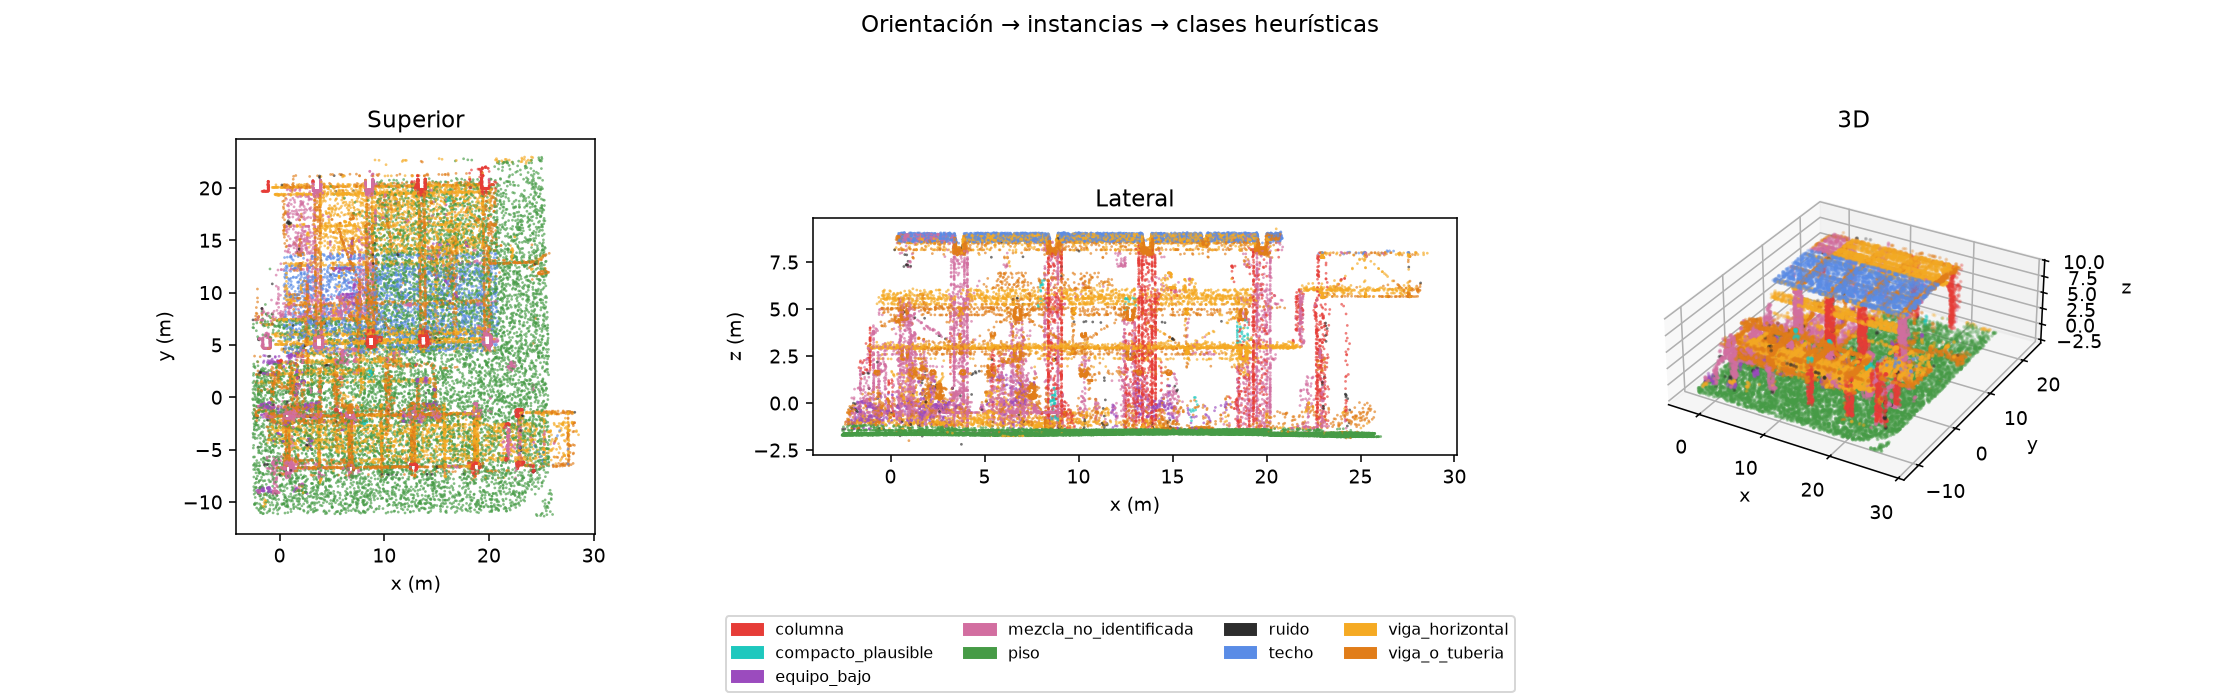

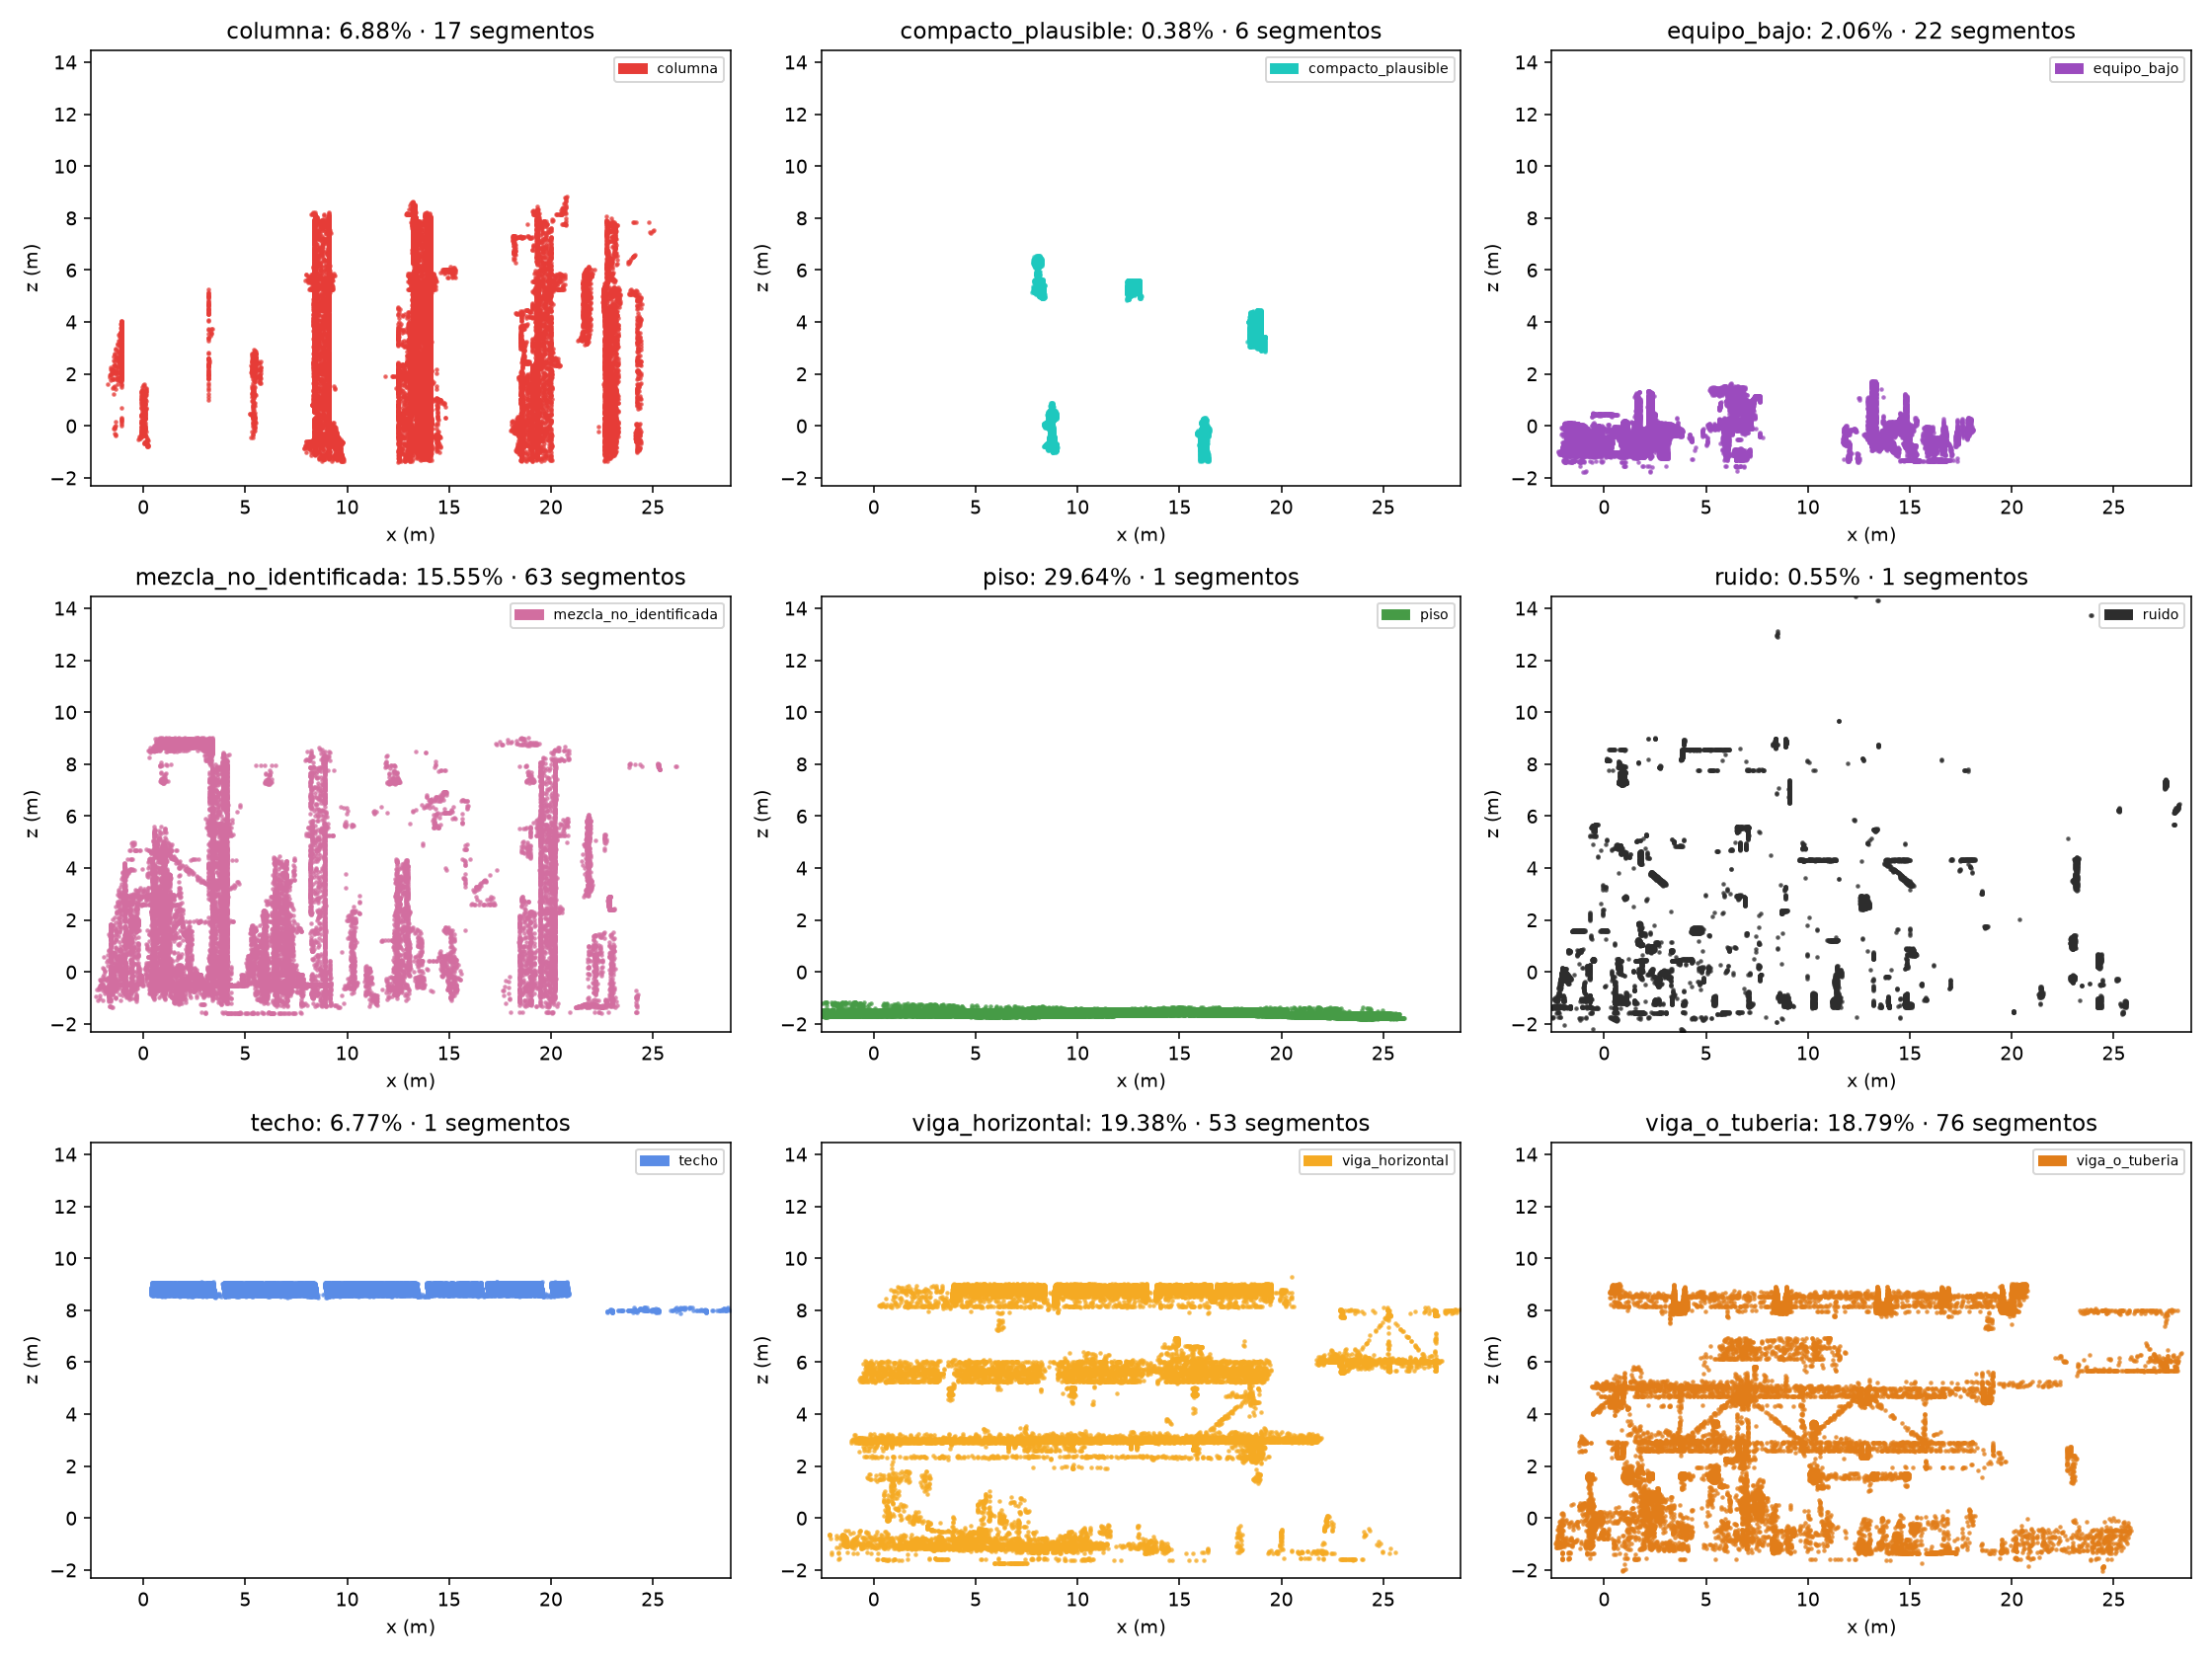

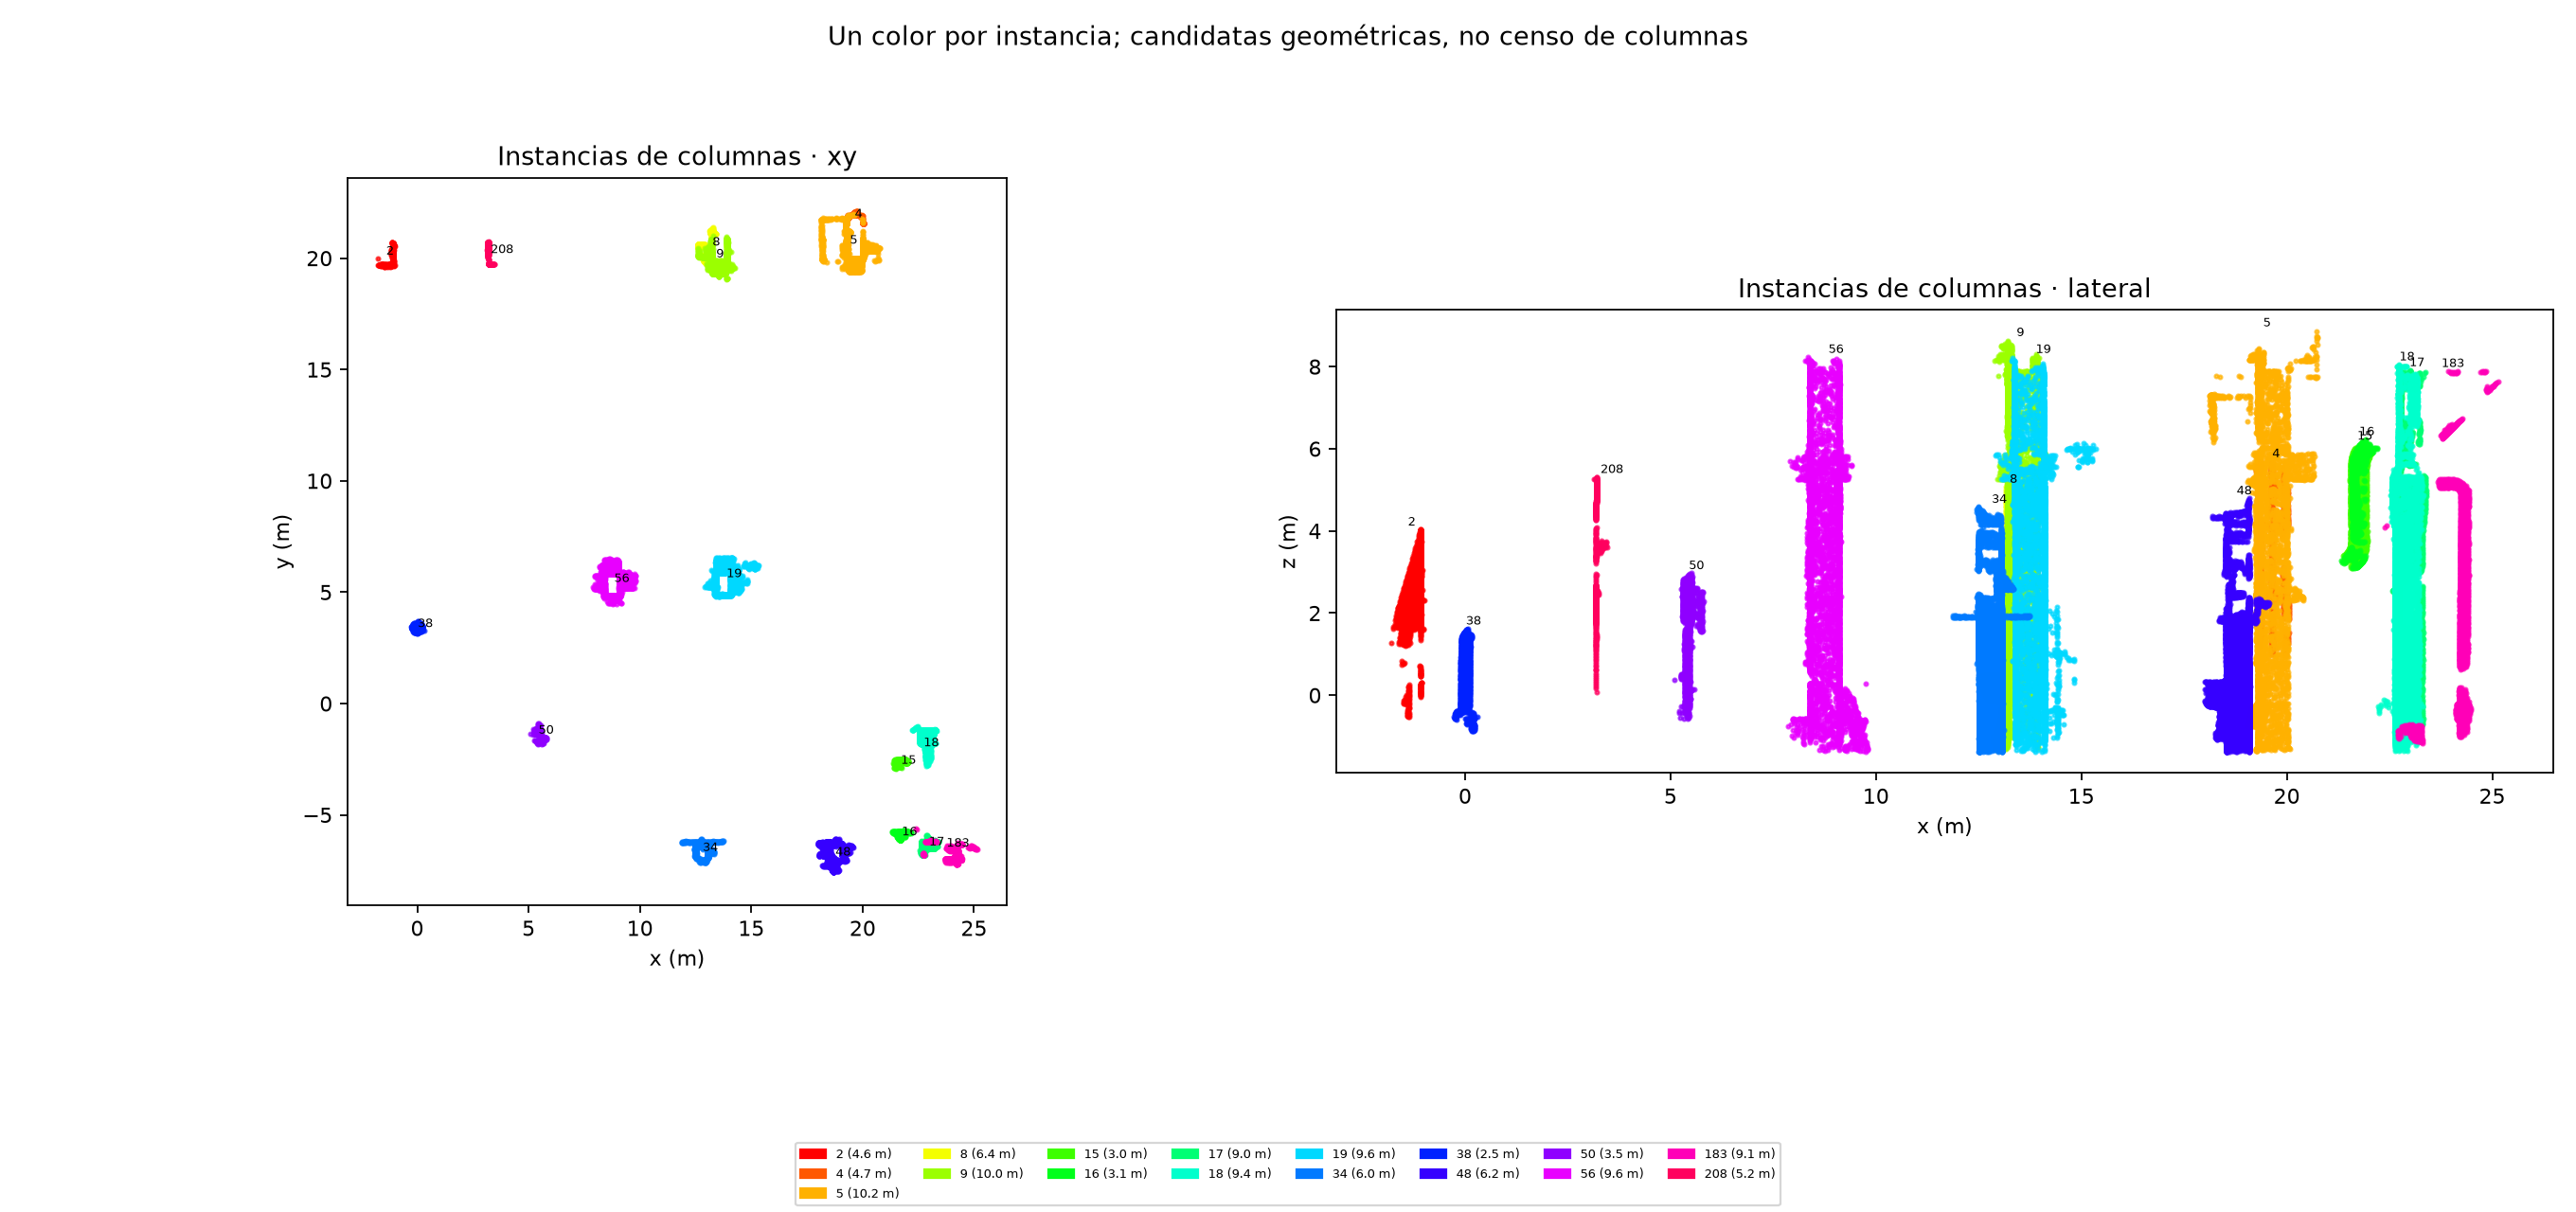

,configuracion,n_segmentos,n_segmentos_500,mayor_segmento_pct,silhouette_geo,DB_geo,silhouette_geo_K11,DB_geo_K11,ARI_clases_base,NMI_clases_base
0,linea_base_clase,11,11,20.369686,0.145923,2.543944,0.145923,2.543944,NaN,NaN
1,final_HDBSCAN40,239,218,29.644552,-0.295438,4.560424,0.106987,2.589411,0.166176,0.26371


,clase_heuristica,n_segmentos,n_puntos,porcentaje
0,columna,17,113352,6.882244
1,compacto_plausible,6,6202,0.376559
2,equipo_bajo,22,33860,2.055833
3,mezcla_no_identificada,63,256084,15.548314
4,piso,1,488252,29.644552
5,ruido,1,9115,0.553423
6,techo,1,111522,6.771134
7,viga_horizontal,53,319174,19.378866
8,viga_o_tuberia,76,309460,18.789074


,id,x_centro,y_centro,extension_vertical,n_puntos,fuste_alto
3,2,-1.392128,20.161878,4.563890,2315,False
5,4,19.645445,21.832889,4.727686,703,False
6,5,19.424418,20.650186,10.229134,14701,True
9,8,13.254864,20.567499,6.426253,1114,True
10,9,13.422462,20.034349,9.996469,15705,True
16,15,21.715165,-2.707238,3.018980,1230,False
17,16,21.762077,-5.919844,3.135584,870,False
18,17,22.983040,-6.370568,9.024236,5487,True
19,18,22.739146,-1.919477,9.416540,9165,True
20,19,13.889069,5.673618,9.604130,22021,True


{'configuracion': 'HDBSCAN40', 'n_puntos': 1647021, 'n_segmentos': 239, 'clases': ['columna', 'compacto_plausible', 'equipo_bajo', 'mezcla_no_identificada', 'piso', 'ruido', 'techo', 'viga_horizontal', 'viga_o_tuberia'], 'n_segmentos_completo': 239, 'mezcla_pct': 15.548314198786779, 'ruido_completo_pct': 0.553423423259327, 'no_resuelto_pct': 16.101737622046105, 'n_columnas': 17, 'n_columnas_altas': 11, 'n_columnas_altas_distintas': 9, 'n_compactos': 6, 'segundos_pipeline': 4.126965584000573, 'piso_en_un_segmento': np.float64(100.0), 'piso_n_segmentos': 1, 'piso_soporte': 488252, 'n_segmentos_500': 218, 'cobertura_500_pct': 97.95320703278915, 'mayor_segmento_pct': 29.644552194537898, 'silhouette_geo': -0.2954376486109213, 'DB_geo': 4.560423575548984, 'silhouette_base_pareado': 0.14592301054855195, 'DB_base_pareado': 2.5439438057753834, 'n_soporte_pareado': 91981, 'n_geo_K11': 11, 'silhouette_geo_K11': 0.1069871960264979, 'DB_geo_K11': 2.5894110005315003, 'ARI_clases_base': 0.16617573978

In [2]:
choice=json.loads((CACHE/'exp_mejor_config.json').read_text());print(choice)
run=pipeline(cloud,cloud['xyz'],**choice['parametros']);save_run('final',run)
labels=run['labels'];np.save(CACHE/'exp_final_ids.npy',labels)
summary,totals,classes=maps_and_totals(run)
summary['bbox']=summary.apply(lambda row:json.dumps([[row.x_min,row.y_min,row.z_min],[row.x_max,row.y_max,row.z_max]]),axis=1)
summary.to_csv(ENT/'final_segmentos.csv',index=False);totals.to_csv(OUT/'exp_porcentajes_clases.csv',index=False)
legend=pd.DataFrame([dict(clase_heuristica=name,R=CLASS_COLORS[name][0],G=CLASS_COLORS[name][1],B=CLASS_COLORS[name][2]) for name in sorted(totals.clase_heuristica)])
legend.to_csv(ENT/'final_leyenda.csv',index=False)
colors=np.empty((len(labels),3),np.uint8)
for label in np.unique(labels):colors[labels==label]=CLASS_COLORS[classes[int(label)]]
write_ply(ENT/'final_segmentos.ply',cloud['xyz'],colors,cloud['normals'])
restored=read_ply(ENT/'final_segmentos.ply')
assert np.array_equal(restored['xyz'],cloud['xyz']) and np.array_equal(restored['normals'],cloud['normals'])
assert np.array_equal(restored['rgb'],colors) and colors.dtype==np.uint8 and summary.n_puntos.sum()==1647021
view(cloud['xyz'],labels,'05_final','Orientación → instancias → clases heurísticas',classes)
# Panel por clase con escala y colores comunes.
names=totals.clase_heuristica.tolist();fig,axes=plt.subplots(int(np.ceil(len(names)/3)),3,figsize=(16,4*int(np.ceil(len(names)/3))),squeeze=False)
for ax,name in zip(axes.flat,names):
    ids=summary.loc[summary.clase_heuristica==name,'id'].to_numpy();points=np.flatnonzero(np.isin(labels,ids))
    take=np.random.default_rng(0).choice(points,min(18000,len(points)),replace=False);p=cloud['xyz'][take]
    pct=float(totals.loc[totals.clase_heuristica==name,'porcentaje'].iloc[0])
    ax.scatter(p[:,0],p[:,2],s=2,c=[np.array(CLASS_COLORS[name])/255],alpha=.65)
    ax.set(xlim=(cloud['xyz'][:,0].min(),cloud['xyz'][:,0].max()),ylim=(cloud['xyz'][:,2].min(),cloud['xyz'][:,2].max()),xlabel='x (m)',ylabel='z (m)',title=f'{name}: {pct:.2f}% · {len(ids)} segmentos')
    ax.legend(handles=[Patch(color=np.array(CLASS_COLORS[name])/255,label=name)],fontsize=7)
for ax in list(axes.flat)[len(names):]:ax.axis('off')
path=FIG/'exp_05_panel_clases.png';fig.tight_layout();fig.savefig(path,dpi=140);plt.close(fig);display(Image(filename=str(path)))
columns=summary[summary.clase_heuristica=='columna'].copy()
for axis in 'xyz':columns[f'{axis}_centro']=(columns[f'{axis}_min']+columns[f'{axis}_max'])/2
columns['fuste_alto']=columns.extension_vertical>=5
columns['grupo_huella_alta']=-1
from sklearn.cluster import DBSCAN
high=columns[columns.fuste_alto]
if len(high):
    footprint=DBSCAN(eps=1.5,min_samples=1).fit_predict(high[['x_centro','y_centro']])
    columns.loc[high.index,'grupo_huella_alta']=footprint
columns.to_csv(OUT/'exp_columnas_auditoria.csv',index=False)
# Paleta hsv con un tono por ID, guardada para consultar la figura sin ambigüedad.
colpalette=(plt.get_cmap('hsv')(np.linspace(0,.95,max(len(columns),1)))[:,:3]*255).astype(np.uint8)
fig,axes=plt.subplots(1,2,figsize=(17,8));handles=[];colorrows=[]
for i,row in enumerate(columns.itertuples()):
    pointids=np.flatnonzero(labels==row.id);take=np.random.default_rng(0).choice(pointids,min(5000,len(pointids)),replace=False);p=cloud['xyz'][take];c=colpalette[i]/255
    for ax,axis in zip(axes,(1,2)):ax.scatter(p[:,0],p[:,axis],s=3,c=[c],alpha=.7)
    axes[0].text(row.x_centro,row.y_centro,str(row.id),fontsize=6)
    axes[1].text(row.x_centro,row.z_max+.1,str(row.id),fontsize=6)
    handles.append(Patch(color=c,label=f'{row.id} ({row.extension_vertical:.1f} m)'))
    colorrows.append(dict(id=row.id,R=int(colpalette[i,0]),G=int(colpalette[i,1]),B=int(colpalette[i,2])))
axes[0].set(xlabel='x (m)',ylabel='y (m)',title='Instancias de columnas · xy',aspect='equal');axes[1].set(xlabel='x (m)',ylabel='z (m)',title='Instancias de columnas · lateral',aspect='equal')
fig.legend(handles=handles,loc='lower center',ncol=8,fontsize=6)
fig.suptitle('Un color por instancia; candidatas geométricas, no censo de columnas')
fig.tight_layout(rect=(0,.18,1,.94));path=FIG/'exp_05_columnas_instancias.png';fig.savefig(path,dpi=160);plt.close(fig);display(Image(filename=str(path)))
pd.DataFrame(colorrows,columns=['id','R','G','B']).to_csv(OUT/'exp_columnas_colores.csv',index=False)
XGEO=geometry_space();fair=geometric_comparison(XGEO,labels,common_idx,BASE_FULL,classes)
abl=pd.read_csv(ENT/'exp_ablaciones.csv');selected=abl[abl.configuracion==choice['configuracion']].iloc[0]
base_row=abl.iloc[0].to_dict()
# En la tabla final ambas filas usan exactamente el soporte pareado del final.
base_row.update(silhouette_geo=fair['silhouette_base_pareado'],DB_geo=fair['DB_base_pareado'],
    silhouette_geo_K11=fair['silhouette_base_pareado'],DB_geo_K11=fair['DB_base_pareado'],
    n_soporte_pareado=fair['n_soporte_pareado'])
comparison=pd.DataFrame([base_row,dict(configuracion='final_'+choice['configuracion'],
    **evaluate(EVAL,xyz,labels[common_idx],run['planes']),**fair,**mixture_metrics(summary,totals),ARI_media=selected.ARI_media,ARI_std=selected.ARI_std,protocolo_ARI='remuestreo_voxel')])
comparison.to_csv(OUT/'exp_comparacion_final.csv',index=False)
display(comparison[['configuracion','n_segmentos','n_segmentos_500','mayor_segmento_pct','silhouette_geo','DB_geo','silhouette_geo_K11','DB_geo_K11','ARI_clases_base','NMI_clases_base']])
display(totals);display(columns[['id','x_centro','y_centro','extension_vertical','n_puntos','fuste_alto']])
met=mixture_metrics(summary,totals)
finish('05',dict(configuracion=choice['configuracion'],n_puntos=len(labels),n_segmentos=int((summary.id>=0).sum()),
    clases=totals.clase_heuristica.tolist(),**met,n_compactos=int((summary.clase_heuristica=='compacto_plausible').sum()),
    segundos_pipeline=run['seconds'],**floor_metrics(cloud['xyz'],labels,run['planes']),**fair))

## Qué aprendimos / qué falló
Verificamos los **1 647 021 puntos**, mismo orden, xyz y normales. La salida tiene **239 segmentos**, más **9 115 puntos de ruido (0.55%)**. Mezcla baja del **57.43% histórico a 15.55%**, y mezcla+ruido suma **16.10%**. El piso conserva sus **488 252 puntos en un segmento**. No se exporta pared ni truss como clase; vigas y perfiles ambiguos permanecen separados en viga_horizontal/viga_o_tuberia.

Hay **17 segmentos candidatos a columna**, de los cuales **11 son altos y ocupan nueve grupos de huellas xy**. Se cumplen las metas numéricas del proxy, pero no significa recuperar 17 columnas reales ni todas las columnas de la nave. La vista lateral recupera fustes en x≈8.8, 13.4–13.9 y 19.4, y soportes de x≈22–24. En x≈3.3 solo queda un fragmento alto de 5.23 m (ID 208); la columna completa y otras caras aún aparecen en mezcla. Cerca de x≈0.5 no se recupera un fuste completo. Los IDs **8/9** y **17/183** comparten grupos de huella: no debemos contarlos como cuatro columnas físicas. Algunas candidatas pueden ser soportes de equipos o tuberías verticales. La agrupación de huellas tampoco es ground truth.

Aparecen seis compactos de tamaño plausible (0.38% de puntos), pero no hay evidencia suficiente para identificar personas o vehículos. Tampoco confirmamos ninguna tubería por sección circular. Persisten mezcla en 63 segmentos, fragmentación y conexiones en cruces; el crecimiento/fusión puede absorber elementos vecinos. La comparación geométrica con K=11 no supera la base: **0.1070 frente a 0.1459** en silhouette y **2.5894 frente a 2.5439** en DB, usando exactamente el mismo soporte. La mejora defendible es separar más estructura y reducir el residuo desconocido, no afirmar exactitud ni calidad global superior.